In [1]:
import torch
from torch import nn
from d2l import torch as d2l

In [3]:
n_train, n_test, num_inputs, batch_size = 20, 100, 200, 20
true_w, true_b = torch.ones((num_inputs, 1))*0.01, 0.05
train_data = d2l.synthetic_data(true_w, true_b, n_train)
train_iter = d2l.load_array(train_data, batch_size)
test_data = d2l.synthetic_data(true_w, true_b, n_test)
test_iter = d2l.load_array(test_data, batch_size, is_train=False)

In [4]:
def init_params():
    w = torch.normal(0,1, size=(num_inputs,1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    return [w, b]

In [5]:
def l2_penatly(w):
    return torch.sum(w.pow(2))/2

In [12]:
def train(lambd):
    w, b = init_params()
    net, loss = lambda X:d2l.linreg(X, w, b), d2l.squared_loss
    num_epochs, lr = 200, 0.003
    animator = d2l.Animator(xlabel='epochs', ylabel='loss', yscale='log',
                            xlim=[5, num_epochs], legend=['train', 'test'])
    for epoch in range(num_epochs):
        for X, y in train_iter:
            l = loss(net(X), y) + lambd * l2_penatly(w)
            l.sum().backward()
            d2l.sgd([w, b], lr, batch_size)
        if ((epoch+1) % 5 == 0):
            animator.add(epoch+1, (d2l.evaluate_loss(net, train_iter, loss), d2l.evaluate_loss(net, test_iter, loss)))
    print("w 的 l2 范数是：", torch.norm(w).item())

w 的 l2 范数是： 13.639899253845215


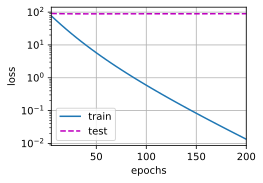

In [13]:
train(0)

w 的 l2 范数是： 2.2215335369110107


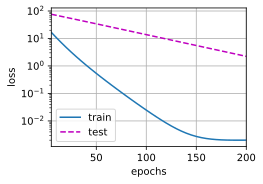

In [14]:
train(lambd=3)

In [17]:
def train_concise(wd):
    net = nn.Sequential(nn.Linear(num_inputs, 1))
    for param in net.parameters():
        param.data.normal_()
    loss = nn.MSELoss(reduce='none')
    num_epochs, lr = 100, 0.003
    trainer = torch.optim.SGD([
        {'params': net[0].weight, 'weight_decay': wd},
        {'params': net[0].bias}
    ], lr=lr)
    animator = d2l.Animator(xlabel='epochs', ylabel='loss', yscale='log',
                            xlim=[5, num_epochs], legend=['train', 'test'])
    for epoch in range(num_epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.mean().backward()
            trainer.step()
        if ((epoch+1) % 5 == 0):
            animator.add(epoch+1, (d2l.evaluate_loss(net, train_iter, loss), d2l.evaluate_loss(net, test_iter, loss)))
    print("w 的 l2 范数是：", net[0].weight.norm().item())

w 的 l2 范数是： 13.34494400024414


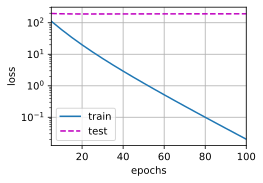

In [18]:
train_concise(0)

w 的 l2 范数是： 5.445959091186523


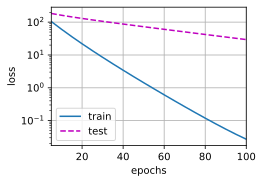

In [22]:
train_concise(3)

Ran command: `python3 -c "
import json

with open('pytorch/chapter_multilayer-perceptrons/weight-decay.ipynb', 'r', encoding='utf-8') as f:
    nb = json.load(f)

for idx, cell in enumerate(nb['cells']):
    if '练习' in ''.join(cell.get('source', [])):
        print(f'=== Cell {idx} ===')
        print(''.join(cell['source']))
"`

以下是 [weight-decay.ipynb](file:///Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_multilayer-perceptrons/weight-decay.ipynb) 课后 6 道练习题的详细分析与解答：

---

### 练习 1
> **题目**：在本节的估计问题中使用 `λ` 的值进行实验。绘制训练和测试精度关于 `λ` 的函数。观察到了什么？

#### 解答与分析：
在实验中改变超参数 `λ`（例如选取 `λ ∈ [0, 0.01, 0.1, 1, 3, 10, 30]`）并记录训练损失与测试损失，可以观察到以下现象：
1. **当 `λ = 0` 时（无正则化）**：
   * 训练损失迅速下降且非常小，但测试损失居高不下且发散。模型记住并拟合了高维特征中的随机噪声，出现**严重过拟合**。
2. **当 `λ` 逐渐增大至合适区间（如 `λ ∈ [1, 5]`）**：
   * 训练损失略有上升，但测试损失显著下降并达到极小值。此时模型约束了权重范数，有效滤除噪声，**泛化性能最佳**。
3. **当 `λ` 过大时（如 `λ > 10`）**：
   * 正则化惩罚项主导了损失函数，强制所有权重 `w` 向 0 收缩，模型容量受到过分限制，训练损失和测试损失均大幅上升，出现**欠拟合**。
4. **曲线形态总结**：
   * **训练误差**关于 `λ` 是**单调递增**的（约束越强，训练集拟合越差）。
   * **测试误差**关于 `λ` 呈现典型的**U 型曲线**（先随方差减小而下降，后随偏差增大而上升），直观体现了**偏差-方差权衡（Bias-Variance Tradeoff）**。

---

### 练习 2
> **题目**：使用验证集来找到最佳值 `λ`。它真的是最优值吗？这有关系吗？

#### 解答与分析：
1. **它不是全局真正意义上的理论“最优值”**：
   * **有限样本与采样噪声**：验证集只是真实未知数据分布的一个小样本采样。在验证集上取得最小误差的 `λ` 只是“样本内经验最优”，容易受验证集本身的采样偏差影响（存在轻微的信息泄漏 / 验证集过拟合）。
   * **离散搜索限制**：超参数调优（如网格搜索、随机搜索）是在离散候选点中选择，通常难以精确命中连续实数空间中的全局极值点。
2. **这有关系吗？（关系不大）**：
   * 机器学习的核心目标是获得**良好的泛化能力**，而不是数学上孤立的最优极值点。
   * 实践中，测试误差曲面在最优点附近通常是相对宽阔和平坦的低谷区域（Flat Basin）。只要选取的 `λ` 落在这个平坦区间内，模型就能显著抑制过拟合，在未见测试数据上表现出稳健且足够优异的性能。

---

### 练习 3
> **题目**：如果我们使用 `∑_i |w_i|` 作为我们选择的惩罚（$L_1$ 正则化），那么更新方程会是什么样子？

#### 解答与分析：
加入 $L_1$ 正则化后，总目标函数定义为：
```text
Loss_total(w, b) = L(w, b) + λ · ∑_j |w_j|
```

对第 `j` 个权重分量 `w_j` 求次梯度（Subgradient）：
```text
∂|w_j| / ∂w_j = sgn(w_j) = {
   +1,  如果 w_j > 0
   -1,  如果 w_j < 0
  [-1, 1] 内的任意值, 如果 w_j = 0
}
```

使用学习率为 `η` 的随机梯度下降，更新方程为：
```text
w_j ← w_j - η · (∂L / ∂w_j + λ · sgn(w_j))
    = w_j - η · λ · sgn(w_j) - η · (∂L / ∂w_j)
```

#### 与 $L_2$ 正则化的对比：
* **$L_2$ 正则化（权重衰减）**：`w ← (1 - η·λ) · w - η · (∂L/∂w)`，每步更新按**比例缩放**权重。权重越大衰减越多，权重越小衰减越轻微，权重不易精确变成 0。
* **$L_1$ 正则化（Lasso）**：每步更新向 0 方向移动**恒定步长** `η · λ`。当权重跨过 0 时会被截断在 0（在优化实现中常配合软阈值算子 Soft-Thresholding），因而能产生**稀疏解（Sparsity）**，常用于特征选择。

---

### 练习 4
> **题目**：我们知道 `||w||² = wᵀ · w`。能找到类似的矩阵方程吗（见 Frobenius 范数）？

#### 解答与分析：
对于矩阵 `W ∈ ℝ^(m × n)`，Frobenius 范数定义为矩阵所有元素平方和的平方根：
```text
||W||_F = √( ∑_{i=1}^m ∑_{j=1}^n W_{ij}² )
```
其平方矩阵方程可以通过**矩阵转置乘积的迹（Trace，即主对角线元素之和）**表示：

```text
||W||_F² = Tr(Wᵀ · W) = Tr(W · Wᵀ)
```

#### 推导说明：
矩阵乘积 `A = Wᵀ · W` 的对角线第 `j` 个元素为：
```text
A_jj = ∑_{i=1}^m (Wᵀ)_{ji} · W_{ij} = ∑_{i=1}^m W_{ij}²
```
对所有对角线元素求和，即计算矩阵的迹：
```text
Tr(Wᵀ · W) = ∑_{j=1}^n A_jj = ∑_{j=1}^n ∑_{i=1}^m W_{ij}² = ||W||_F²
```

---

### 练习 5
> **题目**：回顾训练误差和泛化误差之间的关系。除了权重衰减、增加训练数据、使用适当复杂度的模型之外，还能想出其他什么方法来处理过拟合？

#### 解答与分析：
在现代深度学习中，常用的抗过拟合策略包括：
1. **暂退法（Dropout）**：训练过程中在前向传播时按概率随机将神经元置 0，相当于隐式集成（Ensemble）了指数级数量的小型子网络。
2. **早停法（Early Stopping）**：在训练过程中持续监测验证集误差，一旦验证误差不再下降反而开始上升时提前终止训练，防止模型学到训练集特有的噪声。
3. **数据增强（Data Augmentation）**：无需采集新数据，通过图像翻转、旋转、缩放、裁剪、色彩抖动，或文本同义词替换等手段生成更多样化的训练样本。
4. **归一化层（Batch Normalization / Layer Normalization）**：由于小批量计算均值和方差时带有小样本随机抖动，起到了隐式噪声注入与正则化效果。
5. **标签平滑（Label Smoothing）与噪声注入**：将 one-hot 硬标签软化（如 `[0, 1]` 变为 `[0.05, 0.95]`），或者在输入、隐藏层激活值中添加微量高斯噪声，防止模型对预测产生过度自信。
6. **模型集成（Ensemble Methods）**：训练多个不同架构或不同初始化的模型（如 Bagging、Boosting、Snapshot Ensemble），对输出进行加权平均以显著减小方差。

---

### 练习 6
> **题目**：在贝叶斯统计中，我们使用先验和似然的乘积，通过公式 `P(w | x) ∝ P(x | w) · P(w)` 得到后验。如何得到带正则化的 `P(w)`？

#### 解答与分析：
在贝叶斯估计中，**最大后验估计（Maximum A Posteriori, MAP）**的目标是最大化后验概率：
```text
P(w | D) ∝ P(D | w) · P(w)
```
对其两边取负对数：
```text
-log P(w | D) = -log P(D | w) - log P(w) + 常数项
              =   [经验损失项]  + [正则化惩罚项]
```

#### 1. 对应 $L_2$ 正则化（权重衰减）的先验：高斯先验（Gaussian Prior）
假设权重各个分量 `w_j` 独立同分布，服从均值为 0、方差为 `σ²` 的**高斯正态分布**：
```text
P(w_j) = (1 / (√(2π) · σ)) · exp( - w_j² / (2σ²) )

联合先验概率：
P(w) = ∏_j P(w_j)
```
计算负对数先验：
```text
-log P(w) = ∑_j ( w_j² / (2σ²) ) + 常数
          = (1 / (2σ²)) · ||w||² + 常数
```
令超参数 `λ = 1 / σ²`，则负对数高斯先验正好等价于 $L_2$ 惩罚项 `(λ / 2) · ||w||²`。
* **物理意义**：先验方差 `σ²` 越小（越确信权重接近 0），对应的正则化系数 `λ` 越大。

#### 2. 对应 $L_1$ 正则化（Lasso）的先验：拉普拉斯先验（Laplace Prior）
如果假设权重服从参数为 `b` 的**零均值拉普拉斯分布**：
```text
P(w_j) = (1 / (2b)) · exp( - |w_j| / b )
```
计算负对数先验：
```text
-log P(w) = (1 / b) · ∑_j |w_j| + 常数
```
令 `λ = 1 / b`，正好对应 $L_1$ 惩罚项 `λ · ∑_j |w_j|`。
* **物理意义**：拉普拉斯分布在 0 处呈尖峰状，这种先验假设大部分参数严格集中在 0 附近，从而诱导出了参数的稀疏性。